# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ssarimm/Machine-Learning-Internship---Flyrank/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

### Research question

Can historical search-performance and content characteristics help prioritize pages for human review, and does a reduced-feature machine-learning model rank declining pages more effectively than a simple baseline?

### Decision supported

The goal is to help SEO analysts decide which pages to investigate first. The analysis compares a simple baseline with a Decision Tree evaluated using a client-grouped holdout split, then translates the findings into a transparent, rule-based content action playbook.

The intended outcome is better-informed review prioritization, not automatic content changes. The study does not assume that observed declines will continue or that refreshing a page will recover its traffic.

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

### Dataset and scope

This analysis uses the anonymized `content_refresh_anonymized.csv` starter dataset supplied for the FlyRank machine-learning internship. The dataset contains 30,000 content records and 44 columns describing content characteristics, search visibility, traffic, engagement, and derived performance indicators.

### Measures used

The available fields include search impressions and clicks over recent and previous 30-day windows, 90-day performance summaries, average search position, content age, time since the last update, content type, search intent, and search-demand measures. The analysis uses `trend_direction` as the observed outcome label and examines whether a reduced set of content and demand characteristics can help prioritize pages for human review.

### Scope and exclusions

The starter dataset is a snapshot of summarized records, not a controlled experiment. The exact snapshot date and the underlying collection process have not yet been verified, so they should not be inferred. Record identifiers and client identifiers are not included in the public-facing results. Where client identifiers are needed to separate clients during model evaluation, they are used only for splitting the data and are excluded from the model features.

The analysis distinguishes observed historical changes from future outcomes. It does not establish why a page declined or whether updating it would improve performance. No private client names, domains, URLs, or raw private queries will be published.

In [9]:

import pandas as pd
from pathlib import Path

DATA_URL = (
    "https://raw.githubusercontent.com/"
    "flyrank-bih/flyrank-ml-internship-starter/"
    "main/data/raw/content_refresh_anonymized.csv"
)

df = pd.read_csv(DATA_URL)

print("Dataset shape:", df.shape)
print("Unique content IDs:", df["content_id"].nunique())
print("Unique clients:", df["client_id"].nunique())
print("\nTarget distribution:")
display(
    df["trend_direction"]
    .value_counts(dropna=False)
    .rename_axis("trend_direction")
    .to_frame("count")
)

assert df.shape == (30000, 44), "Unexpected dataset shape"
assert "trend_direction" in df.columns
print("\nDataset checks passed.")


Dataset shape: (30000, 44)
Unique content IDs: 30000
Unique clients: 32

Target distribution:


,count
trend_direction,
down,16262
stable,5962
up,4388
new,2236
flat,1152



Dataset checks passed.


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

### Research design and target

This is a retrospective, observational classification experiment using the anonymized FlyRank content dataset. The target is `trend_direction`, which records the observed historical performance category of each content item.

For the primary binary experiment, records labeled `down` are assigned a target of 1, while records labeled `up` or `stable` are assigned a target of 0. Records labeled `new` or `flat` are excluded from this experiment because they represent different performance situations. The resulting metrics therefore apply only to the included records, not to every page in the original dataset.

### Features and leakage controls

The reduced-feature model uses nine characteristics: `search_volume`, `competition`, `cpc`, `word_count`, `content_age_days`, `days_since_last_update`, `content_type`, `main_intent`, and `competition_level`.

Client and content identifiers are not model features. The fields used to calculate or directly describe recent performance changes—including `impressions_last_30d`, `impressions_prev_30d`, and `trend_pct`—are excluded from the predictors to reduce target leakage.

### Validation

In [10]:

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
)

# 1. Keep only clearly labeled comparison groups.
eligible = df["trend_direction"].isin(["down", "up", "stable"])
model_df = df.loc[eligible].copy()

model_df["target_decline"] = (
    model_df["trend_direction"] == "down"
).astype(int)

features = [
    "search_volume",
    "competition",
    "cpc",
    "word_count",
    "content_age_days",
    "days_since_last_update",
    "content_type",
    "main_intent",
    "competition_level",
]

X = model_df[features]
y = model_df["target_decline"]
groups = model_df["client_id"]

numeric_features = [
    "search_volume",
    "competition",
    "cpc",
    "word_count",
    "content_age_days",
    "days_since_last_update",
]

categorical_features = [
    "content_type",
    "main_intent",
    "competition_level",
]

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
    ]), numeric_features),

    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])

# 2. Split by client, keeping clients separate across train/test.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42,
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

assert set(groups_train).isdisjoint(set(groups_test))

# 3. Train a shallow decision tree.
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=50,
        class_weight="balanced",
        random_state=42,
    )),
])

model.fit(X_train, y_train)
model_scores = model.predict_proba(X_test)[:, 1]
model_predictions = model.predict(X_test)

# 4. Majority-class baseline: predict the training majority for all.
majority_class = int(y_train.mean() >= 0.5)
baseline_predictions = np.full(len(y_test), majority_class)

# Constant scores are not useful for ranking, so baseline ROC-AUC/AP
# are not presented as ranking metrics.
results = pd.DataFrame([
    {
        "method": "Decision Tree",
        "test_accuracy": accuracy_score(y_test, model_predictions),
        "ROC-AUC": roc_auc_score(y_test, model_scores),
        "Average precision": average_precision_score(y_test, model_scores),
    },
    {
        "method": "Majority baseline",
        "test_accuracy": accuracy_score(y_test, baseline_predictions),
        "ROC-AUC": np.nan,
        "Average precision": np.nan,
    },
])

print("Original rows:", len(df))
print("Included rows:", len(model_df))
print("Excluded new/flat rows:", len(df) - len(model_df))
print("Train rows:", len(train_idx))
print("Test rows:", len(test_idx))
print("Train clients:", groups_train.nunique())
print("Test clients:", groups_test.nunique())
print("Client overlap:", len(set(groups_train) & set(groups_test)))
print("Test decline rate:", round(y_test.mean(), 4))

display(results.round(4))


Original rows: 30000
Included rows: 26612
Excluded new/flat rows: 3388
Train rows: 21514
Test rows: 5098
Train clients: 24
Test clients: 7
Client overlap: 0
Test decline rate: 0.6169


,method,test_accuracy,ROC-AUC,Average precision
0,Decision Tree,0.5981,0.5983,0.676
1,Majority baseline,0.6169,NaN,NaN


In [11]:

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    average_precision_score,
)

# Constant scores: the baseline has no ranking information.
baseline_scores = np.full(len(y_test), y_train.mean())

comparison = pd.DataFrame([
    {
        "method": "Decision Tree",
        "accuracy": accuracy_score(y_test, model_predictions),
        "ROC-AUC": roc_auc_score(y_test, model_scores),
        "average_precision": average_precision_score(y_test, model_scores),
    },
    {
        "method": "Majority baseline",
        "accuracy": accuracy_score(y_test, baseline_predictions),
        "ROC-AUC": roc_auc_score(y_test, baseline_scores),
        "average_precision": average_precision_score(y_test, baseline_scores),
    },
])

display(comparison.round(4))
print("Test-set decline rate:", round(y_test.mean(), 4))


,method,accuracy,ROC-AUC,average_precision
0,Decision Tree,0.5981,0.5983,0.6760
1,Majority baseline,0.6169,0.5000,0.6169


Test-set decline rate: 0.6169


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

## 4. Results

### Evaluation setup

The original dataset contained 30,000 records. The binary experiment retained 26,612 records labeled `down`, `up`, or `stable`, excluding 3,388 records labeled `new` or `flat`. A client-grouped split allocated 21,514 records to training and 5,098 to testing. The training and test sets contained 24 and 7 clients, respectively, with no client overlap.

### Model performance

The reduced-feature Decision Tree achieved 59.81% test accuracy, compared with 61.69% for the majority-class baseline. Thus, the tree's accuracy was 1.88 percentage points lower than the baseline.

The Decision Tree achieved ROC-AUC of 0.5983 and average precision of 0.6760. The test-set decline rate was 61.69%, which provides the reference level for interpreting average precision. These initial results suggest limited ranking ability and do not establish that the model is useful enough for operational prioritization.

### Practical interpretation

The model did not outperform the majority-class baseline on accuracy. Its ranking metrics warrant further investigation, but they do not establish reliable predictive performance across clients. The results support further validation—not automated content changes or claims that refreshing a page will recover traffic.

## 5. Limitations

*What this work cannot claim.*

## 5. Limitations

This analysis has several limitations that affect how its results should be interpreted.

- **Observational data:** The dataset contains historical summaries, not a controlled experiment. Associations between content characteristics and performance changes do not establish causation.
- **Restricted target population:** The binary experiment excludes records labeled `new` or `flat`. Its results apply only to the remaining `down`, `up`, and `stable` records.
- **Limited model performance:** The Decision Tree achieved 59.81% accuracy, below the 61.69% majority-class baseline. Its ROC-AUC of 0.5983 suggests limited ability to distinguish declining records from the comparison group.
- **Client generalization:** The test set contains seven clients, compared with 24 in training. Although there is no client overlap, performance may vary across different client populations and split choices.
- **No temporal validation:** A client-grouped split does not establish that the model will perform well on future periods. A separate time-based evaluation would be needed to assess that.
- **No causal evidence for refreshing:** The analysis does not show that updating a page will reverse a decline or increase traffic.
- **Data and measurement limits:** The dataset contains summarized fields and derived labels. Their definitions and collection process may limit interpretation, and results may change if the underlying data or labeling rules change.

The model should therefore be treated as an exploratory research result, not a production-ready prediction system. Any practical use should retain human review, validate the underlying evidence, and monitor outcomes before operational adoption.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

In [12]:

playbook_fields = [
    "trend_direction",
    "days_since_last_update",
    "search_volume",
    "content_age_days",
    "impressions_90d",
]

for field in playbook_fields:
    print(f"{field}: {'Available' if field in df.columns else 'Missing'}")


trend_direction: Available
days_since_last_update: Available
search_volume: Available
content_age_days: Available
impressions_90d: Available


In [13]:

import pandas as pd

# Work on a copy; preserve the original dataset.
playbook = df.copy()

# Define transparent, interpretable review signals.
playbook["observed_decline"] = (
    playbook["trend_direction"] == "down"
)

playbook["is_stale"] = (
    playbook["days_since_last_update"] >= 180
)

# Use the established threshold for this playbook.
playbook["has_search_demand"] = (
    playbook["search_volume"] >= 20
)

# Calculate a rule-based priority score (maximum = 6).
playbook["priority_score"] = (
    playbook["observed_decline"].astype(int) * 3
    + playbook["is_stale"].astype(int) * 2
    + playbook["has_search_demand"].astype(int)
)

# Assign an action based on the combination of signals.
def recommend_action(row):
    decline = row["observed_decline"]
    stale = row["is_stale"]
    demand = row["has_search_demand"]

    if decline and stale and demand:
        return "Review refresh opportunity; verify intent and content gaps"
    elif decline and stale:
        return "Diagnose decline and check whether content is outdated"
    elif decline and demand:
        return "Audit search intent, content gaps, and technical issues"
    elif decline:
        return "Investigate observed decline before choosing an action"
    elif stale and demand:
        return "Review freshness and accuracy; refresh only if justified"
    elif stale:
        return "Check whether content is outdated"
    else:
        return "Monitor performance and assess content usefulness"

playbook["recommended_action"] = playbook.apply(
    recommend_action, axis=1
)

# Rank by score, then demand, for a human-review queue.
review_queue = (
    playbook.loc[playbook["priority_score"] > 0]
    .sort_values(
        ["priority_score", "search_volume"],
        ascending=[False, False],
    )
    .reset_index(drop=True)
)

print("Total dataset rows:", len(playbook))
print("Rows in review queue:", len(review_queue))
print("Maximum priority score:", playbook["priority_score"].max())

print("\nPriority-score distribution:")
display(
    review_queue["priority_score"]
    .value_counts()
    .sort_index(ascending=False)
    .rename_axis("priority_score")
    .to_frame("number_of_pages")
)

print("\nRecommended actions:")
display(
    review_queue["recommended_action"]
    .value_counts()
    .rename_axis("recommended_action")
    .to_frame("number_of_pages")
)

print("\nExample review queue (first 10 rows):")
display(
    review_queue[
        [
            "priority_score",
            "observed_decline",
            "is_stale",
            "has_search_demand",
            "recommended_action",
        ]
    ].head(10)
)


Total dataset rows: 30000
Rows in review queue: 20825
Maximum priority score: 6

Priority-score distribution:


,number_of_pages
priority_score,
6,5
5,77
4,4662
3,11520
2,90
1,4471



Recommended actions:


,number_of_pages
recommended_action,
Investigate observed decline before choosing an action,11518
"Audit search intent, content gaps, and technical issues",4662
Monitor performance and assess content usefulness,4471
Check whether content is outdated,90
Diagnose decline and check whether content is outdated,77
Review refresh opportunity; verify intent and content gaps,5
Review freshness and accuracy; refresh only if justified,2



Example review queue (first 10 rows):


,priority_score,observed_decline,is_stale,has_search_demand,recommended_action
0,6,True,True,True,Review refresh opportunity; verify intent and ...
1,6,True,True,True,Review refresh opportunity; verify intent and ...
2,6,True,True,True,Review refresh opportunity; verify intent and ...
3,6,True,True,True,Review refresh opportunity; verify intent and ...
4,6,True,True,True,Review refresh opportunity; verify intent and ...
5,5,True,True,False,Diagnose decline and check whether content is ...
6,5,True,True,False,Diagnose decline and check whether content is ...
7,5,True,True,False,Diagnose decline and check whether content is ...
8,5,True,True,False,Diagnose decline and check whether content is ...
9,5,True,True,False,Diagnose decline and check whether content is ...


## 6. Ranked recommendations

The rule-based playbook prioritizes records using three transparent signals: observed decline, content age since the last update, and search demand. Decline contributes three points, staleness contributes two, and search demand contributes one. Records with a positive score enter the review queue and are sorted by score, with search demand used as a secondary ordering criterion.

The highest-priority group contains records showing all three signals. These records should receive human review to verify search intent, accuracy, content gaps, and possible technical issues before any refresh decision is made. Other combinations receive narrower diagnostic recommendations based on the signals present.

The score is a prioritization heuristic, not a learned probability or a validated estimate of future performance. It may favor pages with more observable signals, and it does not prove that updating a page will improve outcomes. Reviewers should verify the underlying data and select an action only when supported by evidence.

The queue is intended to support analyst triage. It should not trigger automatic content changes, and it should be evaluated against reviewer judgments and subsequent observed outcomes before being adopted operationally.

## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

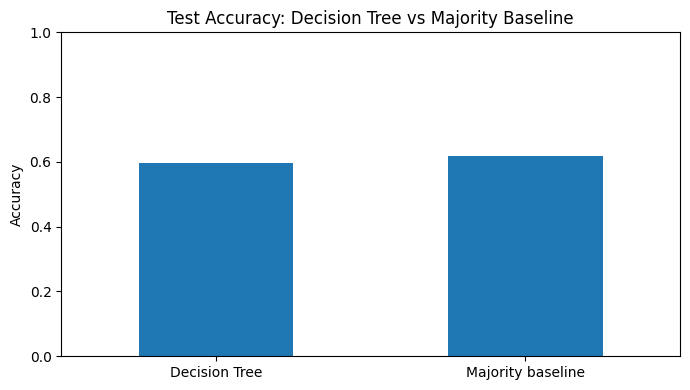

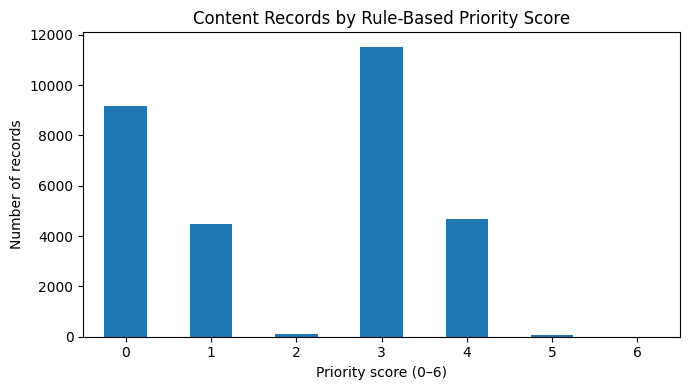

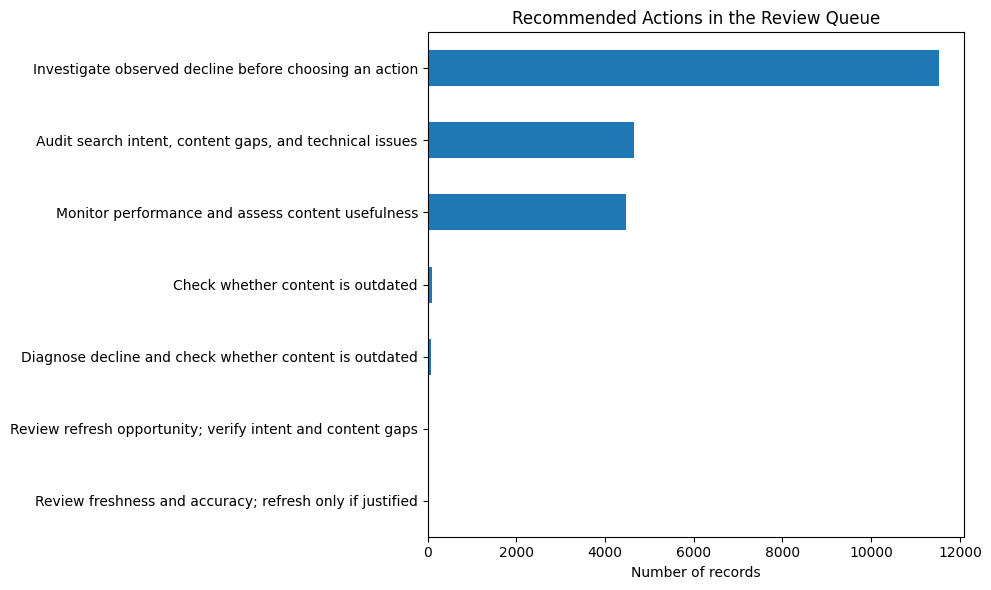

Charts saved:
- chart_model_accuracy.png
- chart_priority_distribution.png
- chart_recommended_actions.png


In [14]:

import matplotlib.pyplot as plt

# Chart 1: Model versus baseline accuracy
accuracy_data = comparison.set_index("method")["accuracy"]

plt.figure(figsize=(7, 4))
accuracy_data.plot(kind="bar")
plt.title("Test Accuracy: Decision Tree vs Majority Baseline")
plt.ylabel("Accuracy")
plt.xlabel("")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("chart_model_accuracy.png", dpi=200, bbox_inches="tight")
plt.show()

# Chart 2: Distribution of priority scores, including score 0
score_counts = (
    playbook["priority_score"]
    .value_counts()
    .reindex(range(7), fill_value=0)
    .sort_index(ascending=False)
)

plt.figure(figsize=(7, 4))
score_counts.sort_index().plot(kind="bar")
plt.title("Content Records by Rule-Based Priority Score")
plt.xlabel("Priority score (0–6)")
plt.ylabel("Number of records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("chart_priority_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

# Chart 3: Recommended actions in the review queue
action_counts = review_queue["recommended_action"].value_counts().sort_values()

plt.figure(figsize=(10, 6))
action_counts.plot(kind="barh")
plt.title("Recommended Actions in the Review Queue")
plt.xlabel("Number of records")
plt.ylabel("")
plt.tight_layout()
plt.savefig("chart_recommended_actions.png", dpi=200, bbox_inches="tight")
plt.show()

print("Charts saved:")
print("- chart_model_accuracy.png")
print("- chart_priority_distribution.png")
print("- chart_recommended_actions.png")


In [15]:

summary_table = pd.DataFrame([
    ["Original dataset", len(df)],
    ["Records included in model evaluation", len(model_df)],
    ["Records excluded from binary experiment", len(df) - len(model_df)],
    ["Records in review queue", len(review_queue)],
    ["Records scoring 6", int((playbook["priority_score"] == 6).sum())],
    ["Records scoring 5 or 6", int((playbook["priority_score"] >= 5).sum())],
], columns=["Measure", "Value"])

display(summary_table)

# Public-safe aggregate outputs
summary_table.to_csv("table_capstone_summary.csv", index=False)
comparison.to_csv("table_model_comparison.csv", index=False)
action_counts.rename("number_of_records").to_csv(
    "table_recommended_actions.csv"
)

print("Summary tables saved.")


,Measure,Value
0,Original dataset,30000
1,Records included in model evaluation,26612
2,Records excluded from binary experiment,3388
3,Records in review queue,20825
4,Records scoring 6,5
5,Records scoring 5 or 6,82


Summary tables saved.


# ## ML-12 — Five-Minute Demo Outline

### 0:00–0:45 — Research question
Can historical content and search-demand characteristics help prioritize pages for human review when search performance declines?

### 0:45–1:45 — Method
I analyzed 30,000 anonymized content records. I retained 26,612 records labeled `down`, `up`, or `stable`, selected nine reduced features, and compared a Decision Tree with a majority-class baseline using a client-grouped holdout split.

### 1:45–2:45 — One chart
Show the chart comparing Decision Tree and baseline accuracy. Explain that the Decision Tree achieved 59.81% accuracy, while the baseline achieved 61.69%.

### 2:45–3:45 — One honest result
The Decision Tree did not outperform the baseline on accuracy. Its ROC-AUC was 0.5983, indicating limited ability to distinguish declining from non-declining records.

### 3:45–5:00 — One recommendation
Use the rule-based review queue to help analysts prioritize pages for investigation. Review search intent, content accuracy, possible content gaps, and technical issues before deciding whether to refresh a page. Further validation is needed before operational use.

# ## ML-12 — Shareable Project Summaries

### Social post

For my FlyRank ML capstone, I explored how to prioritize content pages for human review when search performance declines.

Using 30,000 anonymized content records, I compared a reduced-feature Decision Tree with a majority-class baseline using a client-grouped holdout split. I also built a transparent, rule-based review queue using observed decline, content freshness, and search demand.

One important lesson: a model isn't automatically useful just because it runs. My Decision Tree achieved 59.81% accuracy, below the 61.69% baseline, highlighting the importance of honest evaluation and practical recommendations.

### Employer-facing summary

I built a machine-learning analysis using 30,000 anonymized FlyRank content records to investigate how declining pages could be prioritized for human review. I compared a reduced-feature Decision Tree against a majority-class baseline using a client-grouped holdout split and developed a rule-based review queue using content and search-demand signals. The model did not outperform the baseline on accuracy, demonstrating my focus on honest evaluation, transparent decision rules, and responsible application of machine learning.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
